# SMS Guard: задания 3–7

Весь ноутбук самодостаточный: код проекта и данные встроены в первую ячейку.

**Запуск:** Среда выполнения → Выполнить все. Занимает около минуты.

Сайт здесь не запускается: на защите он работает локально.

In [1]:
#@title Подготовка: распаковка кода и данных (просто запустите)
import base64, io, os, sys, zipfile
from pathlib import Path

PROJECT_B64 = """
...
AAsAxAIAAD91AwAAAA==
"""
workdir = Path("sms_guard").resolve()
workdir.mkdir(exist_ok=True)
zipfile.ZipFile(io.BytesIO(base64.b64decode(PROJECT_B64))).extractall(workdir)
os.chdir(workdir)
ROOT = workdir
sys.path.insert(0, str(ROOT))
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
(ROOT / "data" / "processed").mkdir(parents=True, exist_ok=True)
print("Готово: код и данные распакованы.")

Готово: код и данные распакованы.


# Задания 3–4. Загрузка и очистка данных

In [2]:
from ml.data.clean_sms import OUTPUT_FILE as CLEAN_FILE, clean_dataframe, write_report
from ml.data.load_sms import OUTPUT_FILE as RAW_FILE, describe, load_sms

raw = load_sms()
describe(raw)
raw.to_csv(RAW_FILE, index=False, encoding="utf-8")

cleaned, report, removed = clean_dataframe(raw)
cleaned.to_csv(CLEAN_FILE, index=False, encoding="utf-8")
print()
for step, value in report:
    print(f"{step}: {value}")

Строк: 5574
Типы столбцов:
id        int64
text     object
label     int64
dtype: object

ham (0): 4827 (86.60%)
spam (1): 747 (13.40%)

Примеры класса 0:
  - Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
  - Ok lar... Joking wif u oni...
  - U dun say so early hor... U c already then say...
  - Nah I don't think he goes to usf, he lives around here though
  - Even my brother is not like to speak with me. They treat me like aids patent.

Примеры класса 1:
  - Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
  - FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
  - WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.



Исходных записей: 5574
Изменено нормализацией (регистр, токены, пробелы): 5536
Содержат токен <url>: 151
Содержат токен <email>: 7
Содержат токен <phone>: 400
Содержат токен <money>: 407
Содержат токен <num>: 1386
Удалено пустых после очистки: 0
Удалено дубликатов по text_clean, ham (0): 310
Удалено дубликатов по text_clean, spam (1): 129
Осталось записей: 5135


# Задание 5. Исследовательский анализ SMS (EDA)

Анализ выполняется на всём очищенном наборе до обучения; параметры моделей здесь не подбираются.

In [3]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

df = pd.read_csv(ROOT / "data" / "processed" / "sms_clean.csv", encoding="utf-8")
df["class_name"] = df["label"].map({0: "Безопасные (ham)", 1: "Мошеннические (spam)"})
COLORS = {0: "#5b8def", 1: "#c62f2f"}
print(df.shape)
df.head(3)

(5135, 5)


,id,text_raw,text_clean,label,class_name
0,1,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...",0,Безопасные (ham)
1,2,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,0,Безопасные (ham)
2,3,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in <num> a wkly comp to win fa cup ...,1,Мошеннические (spam)


## 1. Распределение классов

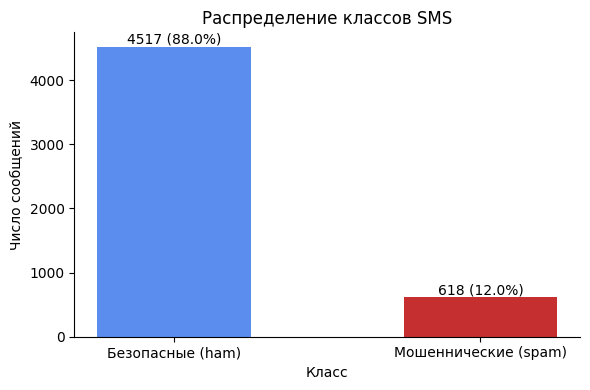

In [4]:
counts = df["label"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Безопасные (ham)", "Мошеннические (spam)"], counts, color=[COLORS[0], COLORS[1]], width=0.5)
for bar, value in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value} ({value / len(df):.1%})", ha="center", va="bottom")
ax.set_title("Распределение классов SMS")
ax.set_xlabel("Класс")
ax.set_ylabel("Число сообщений")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "eda_01_classes.png", dpi=130)
plt.show()

## 2. Длина сообщений по классам

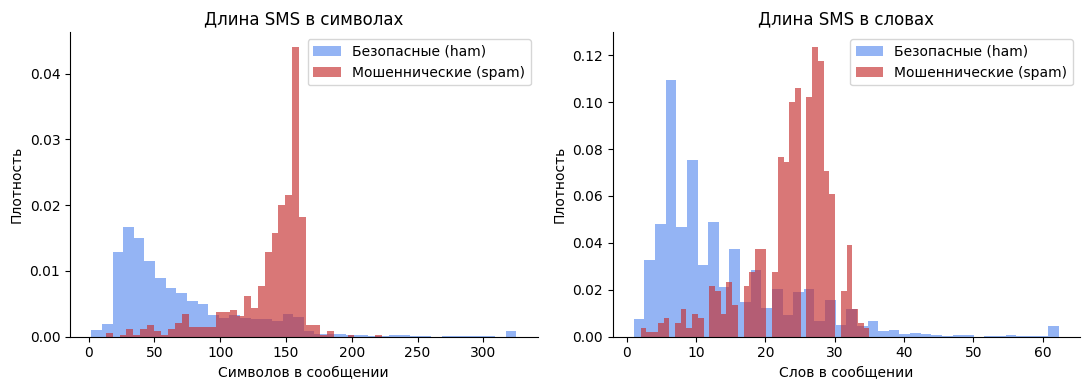

chars        words       
                       mean median  mean median
class_name                                     
Безопасные (ham)       70.9   53.0  14.2   11.0
Мошеннические (spam)  137.5  148.0  23.7   25.0

In [5]:
df["chars"] = df["text_raw"].str.len()
df["words"] = df["text_raw"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column, title, xlabel in [
    (axes[0], "chars", "Длина SMS в символах", "Символов в сообщении"),
    (axes[1], "words", "Длина SMS в словах", "Слов в сообщении"),
]:
    limit = df[column].quantile(0.995)
    for label, name in [(0, "Безопасные (ham)"), (1, "Мошеннические (spam)")]:
        values = df.loc[df["label"] == label, column].clip(upper=limit)
        ax.hist(values, bins=40, density=True, alpha=0.65, color=COLORS[label], label=name)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Плотность")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "eda_02_length.png", dpi=130)
plt.show()
df.groupby("class_name")[["chars", "words"]].agg(["mean", "median"]).round(1)

## 3. Топ-20 слов и биграмм для каждого класса (без стоп-слов)

In [6]:
TOKEN_RE = re.compile(r"[a-zа-яё']{2,}")

def tokens(text):
    return [t for t in TOKEN_RE.findall(text) if t not in ENGLISH_STOP_WORDS]

def top_ngrams(texts, n, k=20):
    counter = Counter()
    for text in texts:
        words = tokens(text)
        counter.update(" ".join(words[i:i + n]) for i in range(len(words) - n + 1))
    return counter.most_common(k)

tables = {}
for label, name in [(0, "ham"), (1, "spam")]:
    texts = df.loc[df["label"] == label, "text_clean"]
    tables[f"{name}: слово"] = [w for w, _ in top_ngrams(texts, 1)]
    tables[f"{name}: кол-во"] = [c for _, c in top_ngrams(texts, 1)]
    tables[f"{name}: биграмма"] = [w for w, _ in top_ngrams(texts, 2)]
    tables[f"{name}: кол-во "] = [c for _, c in top_ngrams(texts, 2)]
pd.DataFrame(tables)

,ham: слово,ham: кол-во,ham: биграмма,ham: кол-во,spam: слово,spam: кол-во,spam: биграмма,spam: кол-во
0,num,1083,lt gt,254,num,1714,num num,278
1,i'm,370,num num,76,money,411,phone num,54
2,gt,288,let know,40,phone,386,num money,51
3,lt,287,wan num,31,free,189,box num,47
4,just,282,good morning,24,txt,133,num free,39
5,ok,254,i'm going,22,url,119,num ppm,38
6,got,228,new year,21,stop,116,money prize,36
7,know,226,num pm,20,ur,115,money cash,35
8,like,224,just got,20,text,107,money min,31
9,good,217,num th,19,mobile,104,pobox num,30


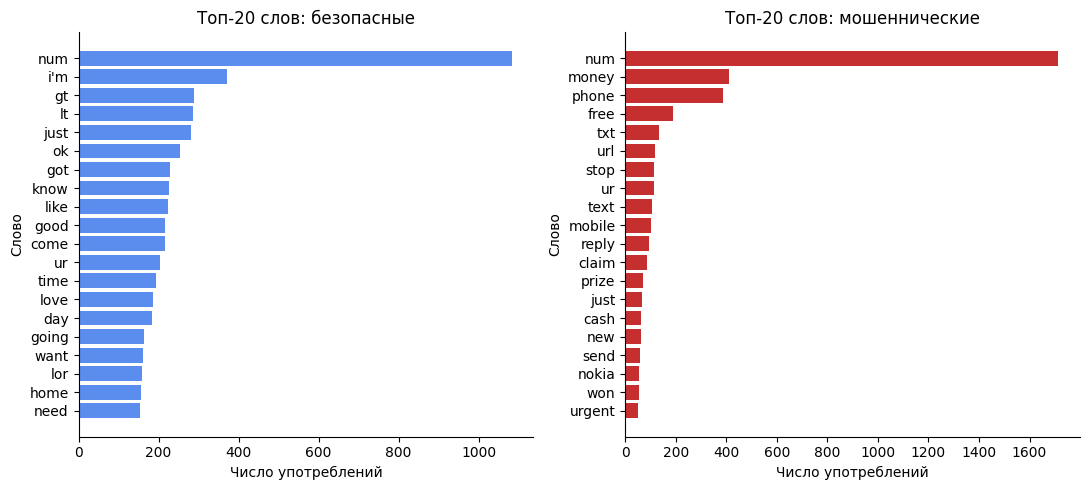

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, label, title in [(axes[0], 0, "Топ-20 слов: безопасные"), (axes[1], 1, "Топ-20 слов: мошеннические")]:
    top = top_ngrams(df.loc[df["label"] == label, "text_clean"], 1)[::-1]
    ax.barh([w for w, _ in top], [c for _, c in top], color=COLORS[label])
    ax.set_title(title)
    ax.set_xlabel("Число употреблений")
    ax.set_ylabel("Слово")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "eda_03_top_words.png", dpi=130)
plt.show()

## 4. Доля сообщений с токенами и восклицательным знаком

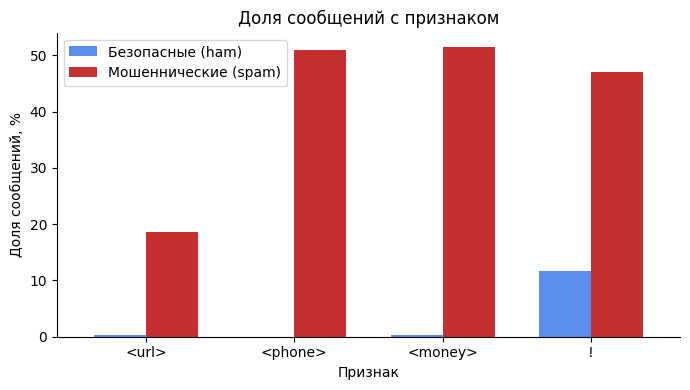

,Безопасные (ham),Мошеннические (spam)
<url>,0.2,18.6
<phone>,0.0,51.0
<money>,0.3,51.5
!,11.7,47.1


In [8]:
marks = {"<url>": "<url>", "<phone>": "<phone>", "<money>": "<money>", "!": "!"}
shares = pd.DataFrame({
    name: df.groupby("label")["text_clean"].apply(lambda s: s.str.contains(mark, regex=False).mean())
    for name, mark in marks.items()
}).T
shares.columns = ["Безопасные (ham)", "Мошеннические (spam)"]

ax = (shares * 100).plot.bar(figsize=(7, 4), color=[COLORS[0], COLORS[1]], rot=0, width=0.7)
ax.set_title("Доля сообщений с признаком")
ax.set_xlabel("Признак")
ax.set_ylabel("Доля сообщений, %")
ax.spines[["top", "right"]].set_visible(False)
ax.figure.tight_layout()
ax.figure.savefig(FIGURES / "eda_04_tokens.png", dpi=130)
plt.show()
(shares * 100).round(1)

## 5. Наблюдения

Числа в выводах вычисляются из данных, поэтому всегда совпадают с набором.

In [9]:
means = df.groupby("label")[["chars", "words"]].mean()
spam_share = df["label"].mean()
top_spam = [w for w, _ in top_ngrams(df.loc[df["label"] == 1, "text_clean"], 1, 5)]
print(f"1. Дисбаланс: spam всего {spam_share:.1%}. Accuracy постоянного ответа «ham» была бы {1 - spam_share:.1%}, поэтому она не подходит как главная метрика.")
print(f"2. Spam длиннее: в среднем {means.loc[1, 'chars']:.0f} символов против {means.loc[0, 'chars']:.0f} у ham.")
print(f"3. Ссылки: <url> встречается в {shares.iloc[0, 1]:.1%} spam и в {shares.iloc[0, 0]:.1%} ham.")
print(f"4. Телефоны: <phone> встречается в {shares.iloc[1, 1]:.1%} spam и в {shares.iloc[1, 0]:.1%} ham.")
print(f"5. Суммы: <money> встречается в {shares.iloc[2, 1]:.1%} spam и в {shares.iloc[2, 0]:.1%} ham.")
print(f"6. Восклицательные знаки: {shares.iloc[3, 1]:.1%} spam и {shares.iloc[3, 0]:.1%} ham.")
print(f"7. Самые частые слова spam: {', '.join(top_spam)}.")

1. Дисбаланс: spam всего 12.0%. Accuracy постоянного ответа «ham» была бы 88.0%, поэтому она не подходит как главная метрика.
2. Spam длиннее: в среднем 137 символов против 71 у ham.
3. Ссылки: <url> встречается в 18.6% spam и в 0.2% ham.
4. Телефоны: <phone> встречается в 51.0% spam и в 0.0% ham.
5. Суммы: <money> встречается в 51.5% spam и в 0.3% ham.
6. Восклицательные знаки: 47.1% spam и 11.7% ham.
7. Самые частые слова spam: num, money, phone, free, txt.


## Как учитывается дисбаланс классов

- Разбиение стратифицированное: доля spam одинакова в train, val и test.
- В Logistic Regression задан `class_weight='balanced'`.
- Качество оценивается по Precision, Recall, F1 и F2 для класса spam, а не по Accuracy.

**Ограничение набора:** spam не равен мошенничеству в строгом смысле (многие сообщения просто реклама), а все тексты английские.

# Задание 6. Разбиение и признаки

Объяснение TF-IDF и N-грамм: `docs/06_features_explained.md`. Код признаков: `ml/features.py`.

In [10]:
import numpy as np
import pandas as pd

from ml.data.split_sms import load_datasets, make_split, save_split
from ml.features import HAND_FEATURE_NAMES, build_feature_union

clean = pd.read_csv(ROOT / "data" / "processed" / "sms_clean.csv", encoding="utf-8")
save_split(make_split(clean))
data = load_datasets()
pd.DataFrame({
    name: {"Записей": len(part), "Доля выборки": len(part) / len(clean), "Доля spam": part["label"].mean()}
    for name, part in data.items()
}).T.round(4)

,Записей,Доля выборки,Доля spam
train,3594.0,0.6999,0.1205
val,770.0,0.1500,0.1195
test,771.0,0.1501,0.1206


## Построение матриц

`fit` вызывается **только на train**; val и test проходят через `transform`.

In [11]:
union = build_feature_union()
X_train = union.fit_transform(data["train"]["text_raw"])
X_val = union.transform(data["val"]["text_raw"])
X_test = union.transform(data["test"]["text_raw"])

word = dict(union.transformer_list)["word"]
char = dict(union.transformer_list)["char"]
print("Слова (1–2 граммы):", len(word.vocabulary_))
print("Символы (3–5 граммы):", len(char.vocabulary_))
print("Ручные признаки:", HAND_FEATURE_NAMES)
for name, matrix, part in [("X_train", X_train, "train"), ("X_val", X_val, "val"), ("X_test", X_test, "test")]:
    assert matrix.shape[0] == len(data[part])
    print(name, matrix.shape)
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

Слова (1–2 граммы): 9116
Символы (3–5 граммы): 23791
Ручные признаки: ['length', 'upper_ratio', 'exclamation_count', 'has_url', 'has_money', 'has_phone', 'rule_group_count']
X_train (3594, 32914)
X_val (770, 32914)
X_test (771, 32914)


## Топ-15 признаков с наибольшим средним TF-IDF по классам (обучающая выборка)

In [12]:
X_word = word.transform(data["train"]["text_raw"])
names = np.array(word.get_feature_names_out())
y = data["train"]["label"].to_numpy()
table = {}
for label, title in [(0, "ham"), (1, "spam")]:
    means = np.asarray(X_word[y == label].mean(axis=0)).ravel()
    order = means.argsort()[::-1][:15]
    table[f"{title}: признак"] = names[order]
    table[f"{title}: средний TF-IDF"] = means[order].round(4)
pd.DataFrame(table)

,ham: признак,ham: средний TF-IDF,spam: признак,spam: средний TF-IDF
0,you,0.0309,<num>,0.1090
1,?,0.0296,<money>,0.0599
2,to,0.0241,<phone>,0.0527
3,the,0.0203,to,0.0463
4,<num>,0.0186,!,0.0429
5,in,0.0182,call,0.0415
6,me,0.0175,<num> <num>,0.0357
7,and,0.0170,your,0.0330
8,it,0.0162,to <num>,0.0313
9,my,0.0160,call <phone>,0.0306


# Задание 7. Baseline-модель SMS

Logistic Regression внутри Pipeline с признаками задания 6. Метрики считаются на **валидационной** выборке; тестовая не используется.

In [13]:
import json
from datetime import date

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score, precision_score, recall_score,
)

from ml.data.split_sms import load_datasets
from ml.features import HAND_FEATURE_NAMES, build_sms_pipeline

data = load_datasets()
train, val = data["train"], data["val"]
pipeline = build_sms_pipeline(LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
pipeline.fit(train["text_raw"], train["label"])
print("Обучено на", len(train), "сообщениях")

Обучено на 3594 сообщениях


## Метрики на валидации

In [14]:
THRESHOLD = 0.5
val_proba = pipeline.predict_proba(val["text_raw"])[:, 1]
val_pred = (val_proba >= THRESHOLD).astype(int)
metrics = {
    "accuracy": accuracy_score(val["label"], val_pred),
    "precision": precision_score(val["label"], val_pred),
    "recall": recall_score(val["label"], val_pred),
    "f1": f1_score(val["label"], val_pred),
}
pd.Series(metrics).round(4).to_frame("Валидация, класс spam")

,"Валидация, класс spam"
accuracy,0.9896
precision,0.9773
recall,0.9348
f1,0.9556


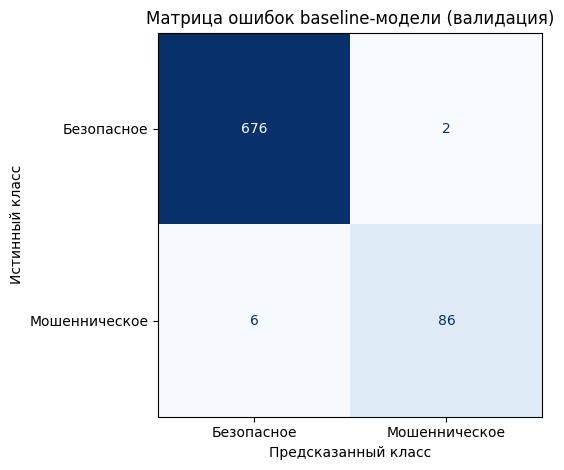

In [15]:
matrix = confusion_matrix(val["label"], val_pred)
display = ConfusionMatrixDisplay(matrix, display_labels=["Безопасное", "Мошенническое"])
display.plot(cmap="Blues", colorbar=False, values_format="d")
display.ax_.set_title("Матрица ошибок baseline-модели (валидация)")
display.ax_.set_xlabel("Предсказанный класс")
display.ax_.set_ylabel("Истинный класс")
display.figure_.tight_layout()
display.figure_.savefig(FIGURES / "baseline_confusion_matrix.png", dpi=130)
plt.show()

## Ошибки: 5 пропусков (FN) и 5 ложных тревог (FP)

In [16]:
errors = val.assign(proba=val_proba, pred=val_pred)
fn = errors[(errors["label"] == 1) & (errors["pred"] == 0)].sort_values("proba").head(5)
fp = errors[(errors["label"] == 0) & (errors["pred"] == 1)].sort_values("proba", ascending=False).head(5)
print(f"Всего FN: {((errors['label'] == 1) & (errors['pred'] == 0)).sum()}, всего FP: {((errors['label'] == 0) & (errors['pred'] == 1)).sum()}\n")
print("FN: мошенничество пропущено")
for row in fn.itertuples():
    print(f"  P={row.proba:.2f} | {row.text_raw}")
print("\nFP: ложная тревога")
for row in fp.itertuples():
    print(f"  P={row.proba:.2f} | {row.text_raw}")
# Настоящих FP меньше пяти, поэтому дополняем список ham с самой высокой вероятностью.
near = errors[(errors["label"] == 0) & (errors["pred"] == 0)].sort_values("proba", ascending=False).head(5 - len(fp))
print("\nНе ошибки, но ближе всего к ложной тревоге:")
for row in near.itertuples():
    print(f"  P={row.proba:.2f} | {row.text_raw}")

Всего FN: 6, всего FP: 2

FN: мошенничество пропущено
  P=0.05 | LIFE has never been this much fun and great until you came in. You made it truly special for me. I won't forget you! enjoy @ one gbp/sms
  P=0.10 | In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)
  P=0.22 | You will be receiving this week's Triple Echo ringtone shortly. Enjoy it!
  P=0.25 | Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!
  P=0.40 | TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the next link sent to ur fone...

FP: ложная тревога
  P=0.86 | Your bill at 3 is £33.65 so thats not bad!
  P=0.64 | Message:some text missing* Sender:Name Missing* *Number Missing *Sent:Date missing *Missing U a lot thats y everything is missing sent via fullons

### Почему модель ошиблась

**Пропуски (FN).** В этих сообщениях нет сильных сигналов: ни телефона, ни суммы, ни ссылки.
- «LIFE has never been...» написано как личное письмо, рекламу выдаёт только «gbp/sms» в конце.
- Викторина про The Simpsons и реклама билетов на Новый год похожи на обычную переписку. Это спам-реклама, а не мошенничество: здесь видно, что spam ≠ мошенничество.
- Сообщения про рингтон и загрузки (TheMob) используют редкую лексику, которой мало в обучении.

**Ложные тревоги (FP).**
- «Your bill at 3 is £33.65» содержит сумму. Токен `<money>` встречается в 51,5% spam и только в 0,3% ham, поэтому модель придаёт ему большой вес.
- Шаблонное сообщение с fullonsms.com содержит адрес сайта, а `<url>` тоже почти не встречается в ham.

**Вывод.** Модель сильно опирается на токены `<money>`, `<phone>` и `<url>`. Мошенник может их обойти, если напишет сообщение без сумм и номеров, поэтому на этапе 2 нужны сравнение алгоритмов и подбор порога (задание 8), а в итоговой оценке риска учитываются ещё правила и анализ ссылок.

## Сохранение и проверка загрузки

In [17]:
ARTIFACTS = ROOT / "ml" / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
joblib.dump(pipeline, ARTIFACTS / "sms_baseline.joblib", compress=3)
meta = {
    "version": "0.1.0-baseline",
    "algorithm": "LogisticRegression(class_weight=balanced, max_iter=1000)",
    "features": ["word_tfidf_1_2", "char_wb_tfidf_3_5"] + HAND_FEATURE_NAMES,
    "threshold": THRESHOLD,
    "metrics_val": {name: round(float(value), 4) for name, value in metrics.items()},
    "trained_at": date.today().isoformat(),
    "train_size": len(train),
}
(ARTIFACTS / "sms_baseline_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print("Размер файла, МБ:", round((ARTIFACTS / "sms_baseline.joblib").stat().st_size / 1024 ** 2, 2))

Размер файла, МБ: 0.44


In [18]:
loaded = joblib.load(ARTIFACTS / "sms_baseline.joblib")
loaded_proba = loaded.predict_proba(val["text_raw"])[:, 1]
assert np.array_equal(loaded_proba, val_proba)
print("Предсказания загруженной модели полностью совпадают.")

Предсказания загруженной модели полностью совпадают.


## Функция predict_sms на новых текстах

`predict_sms` находится в `ml/predictor.py`: она загружает сохранённый pipeline, а `normalize_sms` вызывается внутри него.

In [19]:
from ml.predictor import predict_sms

for text in [
    "Your order #4821 has been shipped and will arrive on Monday.",
    "Congratulations! You won a $1000 gift card. Claim your prize: bit.ly/prize-claim-test",
    "URGENT: Your account will be suspended in 24 hours. Verify now at http://192.0.2.15/account-update",
    "See you at the library tomorrow at 6",
]:
    print(predict_sms(text), "|", text)

{'label': 0, 'probability': 0.2125} | Your order #4821 has been shipped and will arrive on Monday.
{'label': 1, 'probability': 0.9978} | Congratulations! You won a $1000 gift card. Claim your prize: bit.ly/prize-claim-test
{'label': 1, 'probability': 0.9742} | URGENT: Your account will be suspended in 24 hours. Verify now at http://192.0.2.15/account-update
{'label': 0, 'probability': 0.0546} | See you at the library tomorrow at 6


## Предварительно: русский и казахский наборы

Полная проверка относится к заданию 8. Здесь видно, почему для этих языков ML-оценка отмечается как ненадёжная.

In [20]:
custom = pd.read_csv(ROOT / "data" / "raw" / "custom_ru_kk.csv", encoding="utf-8")
custom["y"] = (custom["label"] == "fraud").astype(int)
custom["pred"] = loaded.predict(custom["text"])
rows = {}
for lang, part in custom.groupby("lang"):
    rows[lang] = {
        "Записей": len(part),
        "Recall мошенничества": recall_score(part["y"], part["pred"], zero_division=0),
        "Precision": precision_score(part["y"], part["pred"], zero_division=0),
        "Доля ложных тревог": part.loc[part["y"] == 0, "pred"].mean(),
    }
print("«Привет! Встречаемся завтра...»:", predict_sms("Привет! Встречаемся завтра в 18:00 у входа в библиотеку."))
pd.DataFrame(rows).T.round(3)

«Привет! Встречаемся завтра...»: {'label': 1, 'probability': 0.9302}


,Записей,Recall мошенничества,Precision,Доля ложных тревог
kk,50.0,0.80,0.645,0.44
ru,100.0,0.84,0.667,0.42


Высокий Recall здесь нельзя считать доказательством поддержки языков: модель просто часто отвечает «мошенничество».
- Большая доля безопасных сообщений получает ложную тревогу; даже обычное приглашение на встречу получает высокую вероятность.
- Вероятная причина: русских и казахских слов нет в словаре TF-IDF. После L2-нормализации весь вес вектора приходится на знакомые токены (`!`, `<num>`), а они в обучении связаны со спамом.
- Набор маленький и написан тем же автором, что и словарь правил, поэтому результаты могут быть завышены.

Поэтому в приложении оценка модели для этих языков помечена как ненадёжная и не входит в Risk Score. Полная проверка выполняется в задании 8.